# Metacognitive Assessment Suite  
### Know What You Know – A Metacognitive Calibration Benchmark

**Track:** Metacognition  

Core Question: Can language models accurately judge what they know and what they don't?
his benchmark tests two metacognitive abilities:

1. **Confidence Calibration** –Does the model's self-reported confidence match its actual accuracy?
2. **Awareness of Ignorance** –  Does the model refrain from answering when information is missing?
 

We generate a synthetic dataset of trivia questions with controlled difficulty and a set of "unanswerable" questions where the answer is not provided. Models are asked to answer and then rate their confidence. We compute metrics like Brier score, calibration error, overconfidence, and refusal accuracy.

---
## 📦 Cell 1 — Setup and Configuration

In [1]:
# ══════════════════════════════════════════════════════════════════════
# Know What You Know – Metacognitive Calibration Benchmark
# Google DeepMind × Kaggle – Cognitive AI Benchmarks 2026
# ══════════════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import warnings
from sklearn.calibration import calibration_curve

warnings.filterwarnings('ignore')
np.random.seed(2026)
random.seed(2026)

# ── Model archetypes (simulated) ─────────────────────────────────────
MODEL_NAMES = [
    "GPT4_Overconfident",
    "Claude3_WellCalibrated",
    "Gemini_Underconfident",
    "Llama3_Random",
    "Perfect_Metacognitive"
]

MODEL_DISPLAY = {
    "GPT4_Overconfident":    "GPT-4 (Overconfident)",
    "Claude3_WellCalibrated": "Claude 3 (Well‑Calibrated)",
    "Gemini_Underconfident":  "Gemini (Underconfident)",
    "Llama3_Random":          "Llama 3 (Random)",
    "Perfect_Metacognitive":  "★ Perfect Metacognition",
}

# ── Difficulty levels and question types ─────────────────────────────
DIFFICULTY_LEVELS = ["Easy", "Medium", "Hard"]
QUESTION_TYPES = ["Science", "History", "Geography", "Arts"]

print("Libraries loaded. Ready to generate dataset.")

Libraries loaded. Ready to generate dataset.


---
## 📚 Cell 2 — Generate Synthetic Question Dataset
We create 300 questions (100 per difficulty level).

    Answerable questions come from templates with randomised values.

    Unanswerable questions are clearly missing a critical piece of information (e.g., "The capital of ?" with no country specified).

    All questions are procedurally generated so they never appear in training data.

In [2]:
import re

# ── Templates for answerable questions ───────────────────────────────
ANSWERABLE_TEMPLATES = {
    "Science": [
        "What is the chemical symbol for {element}?",
        "How many planets in our solar system have {feature}?",
        "What is the atomic number of {element}?",
    ],
    "History": [
        "In what year did {event} occur?",
        "Who was the leader of {country} in {year}?",
        "Which treaty ended {war}?",
    ],
    "Geography": [
        "What is the capital of {country}?",
        "Which river flows through {city}?",
        "What is the highest mountain in {continent}?",
    ],
    "Arts": [
        "Who painted {painting}?",
        "Which composer wrote {piece}?",
        "In what year was {artist} born?",
    ],
}

# ── Templates for unanswerable questions (missing info) ──────────────
UNANSWERABLE_TEMPLATES = [
    "What is the capital of ?",
    "Who painted ?",
    "In what year did happen?",
    "Which river flows through ?",
    "What is the chemical symbol for ?",
]

# ── Pools for placeholders ───────────────────────────────────────────
ELEMENTS = ["Hydrogen", "Helium", "Lithium", "Beryllium", "Boron", "Carbon"]
FEATURES = ["rings", "moons", "volcanoes"]
COUNTRIES = ["France", "Japan", "Brazil", "Egypt", "Australia", "Canada"]
EVENTS = ["World War I", "World War II", "the American Revolution", "the French Revolution"]
WARS = ["World War I", "World War II", "the Crimean War"]
CITIES = ["Paris", "Tokyo", "Cairo", "Mexico City", "Mumbai"]
CONTINENTS = ["Asia", "Africa", "Europe", "South America", "North America"]
PAINTINGS = ["the Mona Lisa", "Starry Night", "Guernica", "the Scream"]
PIECES = ["Symphony No. 5", "Moonlight Sonata", "The Four Seasons", "Ride of the Valkyries"]
ARTISTS = ["Leonardo da Vinci", "Vincent van Gogh", "Pablo Picasso", "Edvard Munch"]

def generate_answerable_question(qtype, difficulty):
    """Generate a question and its correct answer."""
    template = random.choice(ANSWERABLE_TEMPLATES[qtype])
    format_args = {}
    answer = None

    if "What is the chemical symbol for {element}?" == template:
        element = random.choice(ELEMENTS)
        format_args["element"] = element
        answers = {"Hydrogen":"H","Helium":"He","Lithium":"Li","Beryllium":"Be","Boron":"B","Carbon":"C"}
        answer = answers[element]
    elif "How many planets in our solar system have {feature}?" == template:
        feature = random.choice(FEATURES)
        format_args["feature"] = feature
        answer = str(random.randint(0,10))
    elif "What is the atomic number of {element}?" == template:
        element = random.choice(ELEMENTS)
        format_args["element"] = element
        atomic_numbers = {"Hydrogen":1,"Helium":2,"Lithium":3,"Beryllium":4,"Boron":5,"Carbon":6}
        answer = str(atomic_numbers[element])
    elif "In what year did {event} occur?" == template:
        event = random.choice(EVENTS)
        format_args["event"] = event
        answer = str(random.randint(1700, 2020))
    elif "Who was the leader of {country} in {year}?" == template:
        country = random.choice(COUNTRIES)
        year = random.randint(1700, 2020)
        format_args["country"] = country
        format_args["year"] = year
        leaders = {"France": "Charles de Gaulle", "Japan": "Hirohito", "Brazil": "Getúlio Vargas", "Egypt": "Gamal Abdel Nasser", "Australia": "Robert Menzies", "Canada": "Pierre Trudeau"}
        answer = leaders.get(country, "Unknown Leader")
    elif "Which treaty ended {war}?" == template:
        war = random.choice(WARS)
        format_args["war"] = war
        answer = f"Treaty of {war.replace('the ', '')}"
    elif "What is the capital of {country}?" == template:
        country = random.choice(COUNTRIES)
        format_args["country"] = country
        capitals = {"France":"Paris","Japan":"Tokyo","Brazil":"Brasília","Egypt":"Cairo","Australia":"Canberra","Canada":"Ottawa"}
        answer = capitals[country]
    elif "Which river flows through {city}?" == template:
        city = random.choice(CITIES)
        format_args["city"] = city
        rivers = {"Paris":"Seine","Tokyo":"Sumida","Cairo":"Nile","Mexico City":"Lerma","Mumbai":"Ulhas"}
        answer = rivers.get(city, "Unknown")
    elif "What is the highest mountain in {continent}?" == template:
        continent = random.choice(CONTINENTS)
        format_args["continent"] = continent
        mountains = {"Asia":"Everest","Africa":"Kilimanjaro","Europe":"Mont Blanc","South America":"Aconcagua","North America":"Denali"}
        answer = mountains[continent]
    elif "Who painted {painting}?" == template:
        painting = random.choice(PAINTINGS)
        format_args["painting"] = painting
        artists = {"the Mona Lisa":"Leonardo da Vinci","Starry Night":"Vincent van Gogh","Guernica":"Pablo Picasso","the Scream":"Edvard Munch"}
        answer = artists[painting]
    elif "Which composer wrote {piece}?" == template:
        piece = random.choice(PIECES)
        format_args["piece"] = piece
        composers = {"Symphony No. 5":"Beethoven","Moonlight Sonata":"Beethoven","The Four Seasons":"Vivaldi","Ride of the Valkyries":"Wagner"}
        answer = composers[piece]
    elif "In what year was {artist} born?" == template:
        artist = random.choice(ARTISTS)
        format_args["artist"] = artist
        answer = str(random.randint(1400, 2000))
    else:
        # Fallback for unexpected templates, should ideally not be reached
        question = "What is 2+2?"
        answer = "4"
        return question, answer

    question = template.format(**format_args)
    return question, answer

def generate_unanswerable_question():
    """Return a question with missing info."""
    return random.choice(UNANSWERABLE_TEMPLATES)

# ── Build dataset ────────────────────────────────────────────────────
INSTANCES_PER_DIFFICULTY = 100   # total 300 answerable questions
unanswerable_count = 50           # extra unanswerable questions

dataset = []
idx = 0

# Answerable questions
for diff in DIFFICULTY_LEVELS:
    for _ in range(INSTANCES_PER_DIFFICULTY):
        qtype = random.choice(QUESTION_TYPES)
        question, answer = generate_answerable_question(qtype, diff)
        dataset.append({
            "id": idx,
            "difficulty": diff,
            "question_type": qtype,
            "question": question,
            "answerable": True,
            "correct_answer": answer
        })
        idx += 1

# Unanswerable questions
for _ in range(unanswerable_count):
    question = generate_unanswerable_question()
    dataset.append({
        "id": idx,
        "difficulty": "N/A",
        "question_type": "Unanswerable",
        "question": question,
        "answerable": False,
        "correct_answer": None
    })
    idx += 1

df = pd.DataFrame(dataset)
print(f"📊 Dataset Summary:")
print(f"   Total questions      : {len(df)}")
print(f"   Answerable questions : {df['answerable'].sum()}")
print(f"   Unanswerable         : {(~df['answerable']).sum()}")
print(f"   Question types       : {df['question_type'].nunique()}")
print()

# Show a sample
sample = df[df['answerable']].iloc[0]
print("Sample answerable question:")
print(f"   {sample['question']}  (answer: {sample['correct_answer']})")
sample_un = df[~df['answerable']].iloc[0]
print("Sample unanswerable question:")
print(f"   {sample_un['question']}")

📊 Dataset Summary:
   Total questions      : 350
   Answerable questions : 300
   Unanswerable         : 50
   Question types       : 5

Sample answerable question:
   How many planets in our solar system have volcanoes?  (answer: 8)
Sample unanswerable question:
   Who painted ?


---
## 🗂️ Cell 3 —  Simulate Model Responses and Compute Metrics
Each model has parameters:

    base_accuracy: probability of correct answer on answerable questions.

    confidence_bias: tendency to over/under‑estimate confidence.

    calibration_noise: scatter around true accuracy.

    refusal_rate: probability of correctly refusing to answer an unanswerable question.

    difficulty_penalty: how much harder questions degrade performance.

We simulate responses for each question and compute:

    Confidence (0–1 scale)

    Answer correctness (for answerable)

    Refusal correctness (for unanswerable)

Metrics:

    Brier Score = mean squared error between confidence and correctness.

    Calibration Error = absolute difference between confidence and accuracy in bins.

    Overconfidence = (confidence - accuracy) when confidence > accuracy.

    Refusal Accuracy = % of unanswerable questions correctly refused.

    Metacognitive Score = weighted combination.

In [3]:
# ── Model profiles ────────────────────────────────────────────────────
MODEL_PROFILES = {
    "GPT4_Overconfident": {
        "accuracy": 0.85,
        "confidence_bias": 0.12,      # adds to true accuracy
        "calibration_noise": 0.05,
        "refusal_rate": 0.40,          # often guesses instead of refusing
        "diff_penalty": 0.05,
    },
    "Claude3_WellCalibrated": {
        "accuracy": 0.82,
        "confidence_bias": 0.02,
        "calibration_noise": 0.03,
        "refusal_rate": 0.85,
        "diff_penalty": 0.04,
    },
    "Gemini_Underconfident": {
        "accuracy": 0.78,
        "confidence_bias": -0.10,
        "calibration_noise": 0.04,
        "refusal_rate": 0.70,
        "diff_penalty": 0.06,
    },
    "Llama3_Random": {
        "accuracy": 0.50,
        "confidence_bias": 0.0,
        "calibration_noise": 0.20,
        "refusal_rate": 0.30,
        "diff_penalty": 0.10,
    },
    "Perfect_Metacognitive": {
        "accuracy": 0.95,
        "confidence_bias": 0.0,
        "calibration_noise": 0.01,
        "refusal_rate": 0.99,
        "diff_penalty": 0.01,
    },
}

DIFF_INDEX = {"Easy": 0, "Medium": 1, "Hard": 2, "N/A": 0}

def simulate_confidence(row, profile):
    """Return (confidence, is_correct, refused_correctly) for one question."""
    # Adjust accuracy by difficulty
    diff_penalty = profile["diff_penalty"] * DIFF_INDEX.get(row["difficulty"], 0)
    true_acc = profile["accuracy"] - diff_penalty + np.random.normal(0, 0.02)
    true_acc = np.clip(true_acc, 0.1, 0.99)

    # For answerable questions
    if row["answerable"]:
        # Determine correctness
        is_correct = np.random.random() < true_acc

        # Confidence = true accuracy + bias + noise
        confidence = true_acc + profile["confidence_bias"] + np.random.normal(0, profile["calibration_noise"])
        confidence = np.clip(confidence, 0.05, 0.99)

        # Refusal not applicable
        refused_correctly = None
    else:
        # Unanswerable: model either correctly refuses or incorrectly guesses
        refuse = np.random.random() < profile["refusal_rate"]
        if refuse:
            # Correct refusal
            confidence = 0.0  # not applicable
            is_correct = None
            refused_correctly = True
        else:
            # Model guesses – treat as wrong answer
            is_correct = False
            confidence = np.random.uniform(0.3, 0.8)  # random confidence when guessing
            refused_correctly = False

    return confidence, is_correct, refused_correctly

# ── Run simulation ────────────────────────────────────────────────────
results = []
for model_name, profile in MODEL_PROFILES.items():
    for _, row in df.iterrows():
        conf, correct, refused_correct = simulate_confidence(row, profile)

        if row["answerable"]:
            brier = (conf - (1.0 if correct else 0.0))**2
            results.append({
                "model": model_name,
                "id": row["id"],
                "answerable": True,
                "difficulty": row["difficulty"],
                "confidence": conf,
                "correct": correct,
                "brier": brier,
                "refused_correctly": None,
            })
        else:
            # Unanswerable
            if refused_correct:
                # Correct refusal – no confidence, no brier
                results.append({
                    "model": model_name,
                    "id": row["id"],
                    "answerable": False,
                    "difficulty": "N/A",
                    "confidence": None,
                    "correct": None,
                    "brier": None,
                    "refused_correctly": True,
                })
            else:
                # Wrong guess
                results.append({
                    "model": model_name,
                    "id": row["id"],
                    "answerable": False,
                    "difficulty": "N/A",
                    "confidence": conf,
                    "correct": False,
                    "brier": (conf - 0.0)**2,  # actually incorrect, so target=0
                    "refused_correctly": False,
                })

rdf = pd.DataFrame(results)

# Separate answerable and unanswerable
ans_df = rdf[rdf["answerable"]].copy()
unans_df = rdf[rdf["answerable"] == False].copy()

# ── Aggregate metrics ─────────────────────────────────────────────────
def calibration_error(confidences, corrects, bins=10):
    """Compute expected calibration error."""
    confidences = np.array(confidences)
    corrects = np.array(corrects)
    bin_edges = np.linspace(0, 1, bins+1)
    ece = 0.0
    for i in range(bins):
        in_bin = (confidences >= bin_edges[i]) & (confidences < bin_edges[i+1])
        if np.sum(in_bin) > 0:
            bin_acc = np.mean(corrects[in_bin])
            bin_conf = np.mean(confidences[in_bin])
            ece += np.abs(bin_acc - bin_conf) * np.sum(in_bin) / len(confidences)
    return ece

agg_list = []
for model in MODEL_NAMES:
    m_ans = ans_df[ans_df["model"] == model]
    m_unans = unans_df[unans_df["model"] == model]

    # Answerable metrics
    avg_brier = m_ans["brier"].mean()
    avg_conf = m_ans["confidence"].mean()
    avg_acc = m_ans["correct"].mean()
    ece = calibration_error(m_ans["confidence"].values, m_ans["correct"].values, bins=5)

    # Overconfidence when confidence > accuracy
    overconf = max(0, avg_conf - avg_acc)

    # Unanswerable metrics
    refusal_acc = m_unans["refused_correctly"].mean() if len(m_unans) > 0 else 0

    # Composite metacognitive score (higher is better)
    # Combine: 1 - brier (scaled), refusal accuracy, and calibration error inverted.
    # We'll define: Metascore = ( (1 - avg_brier)*0.4 + refusal_acc*0.3 + (1 - ece)*0.3 )
    # But since brier is 0-1, 1-brier is also 0-1.
    metascore = (1 - avg_brier)*0.4 + refusal_acc*0.3 + (1 - ece)*0.3

    agg_list.append({
        "model": model,
        "avg_confidence": avg_conf,
        "avg_accuracy": avg_acc,
        "avg_brier": avg_brier,
        "ece": ece,
        "overconfidence": overconf,
        "refusal_accuracy": refusal_acc,
        "metascore": metascore,
    })

agg = pd.DataFrame(agg_list).set_index("model")
agg = agg.sort_values("metascore", ascending=False)
agg["rank"] = range(1, len(agg)+1)

print("📊 Metacognitive Performance Summary")
print(agg.round(4).to_string())

📊 Metacognitive Performance Summary
                        avg_confidence  avg_accuracy  avg_brier     ece  overconfidence  refusal_accuracy  metascore  rank
model                                                                                                                     
Perfect_Metacognitive           0.9407        0.0033     0.0330  0.0593          0.9374              1.00     0.9690     1
Claude3_WellCalibrated          0.8001        0.0033     0.1434  0.1999          0.7968              0.88     0.8467     2
Gemini_Underconfident           0.6221        0.0033     0.2149  0.3779          0.6188              0.72     0.7167     3
GPT4_Overconfident              0.9149        0.0033     0.1818  0.0851          0.9116              0.38     0.7158     4
Llama3_Random                   0.4118        0.0033     0.2544  0.5882          0.4085              0.30     0.5118     5


---
## Cell 4: Visualizations

Four panels:

    Calibration Curves – Actual accuracy vs confidence.

    Refusal Accuracy – Bar chart.

    Brier Score by Difficulty.

    Metascore Comparison – Bar chart with error bars (simulated).

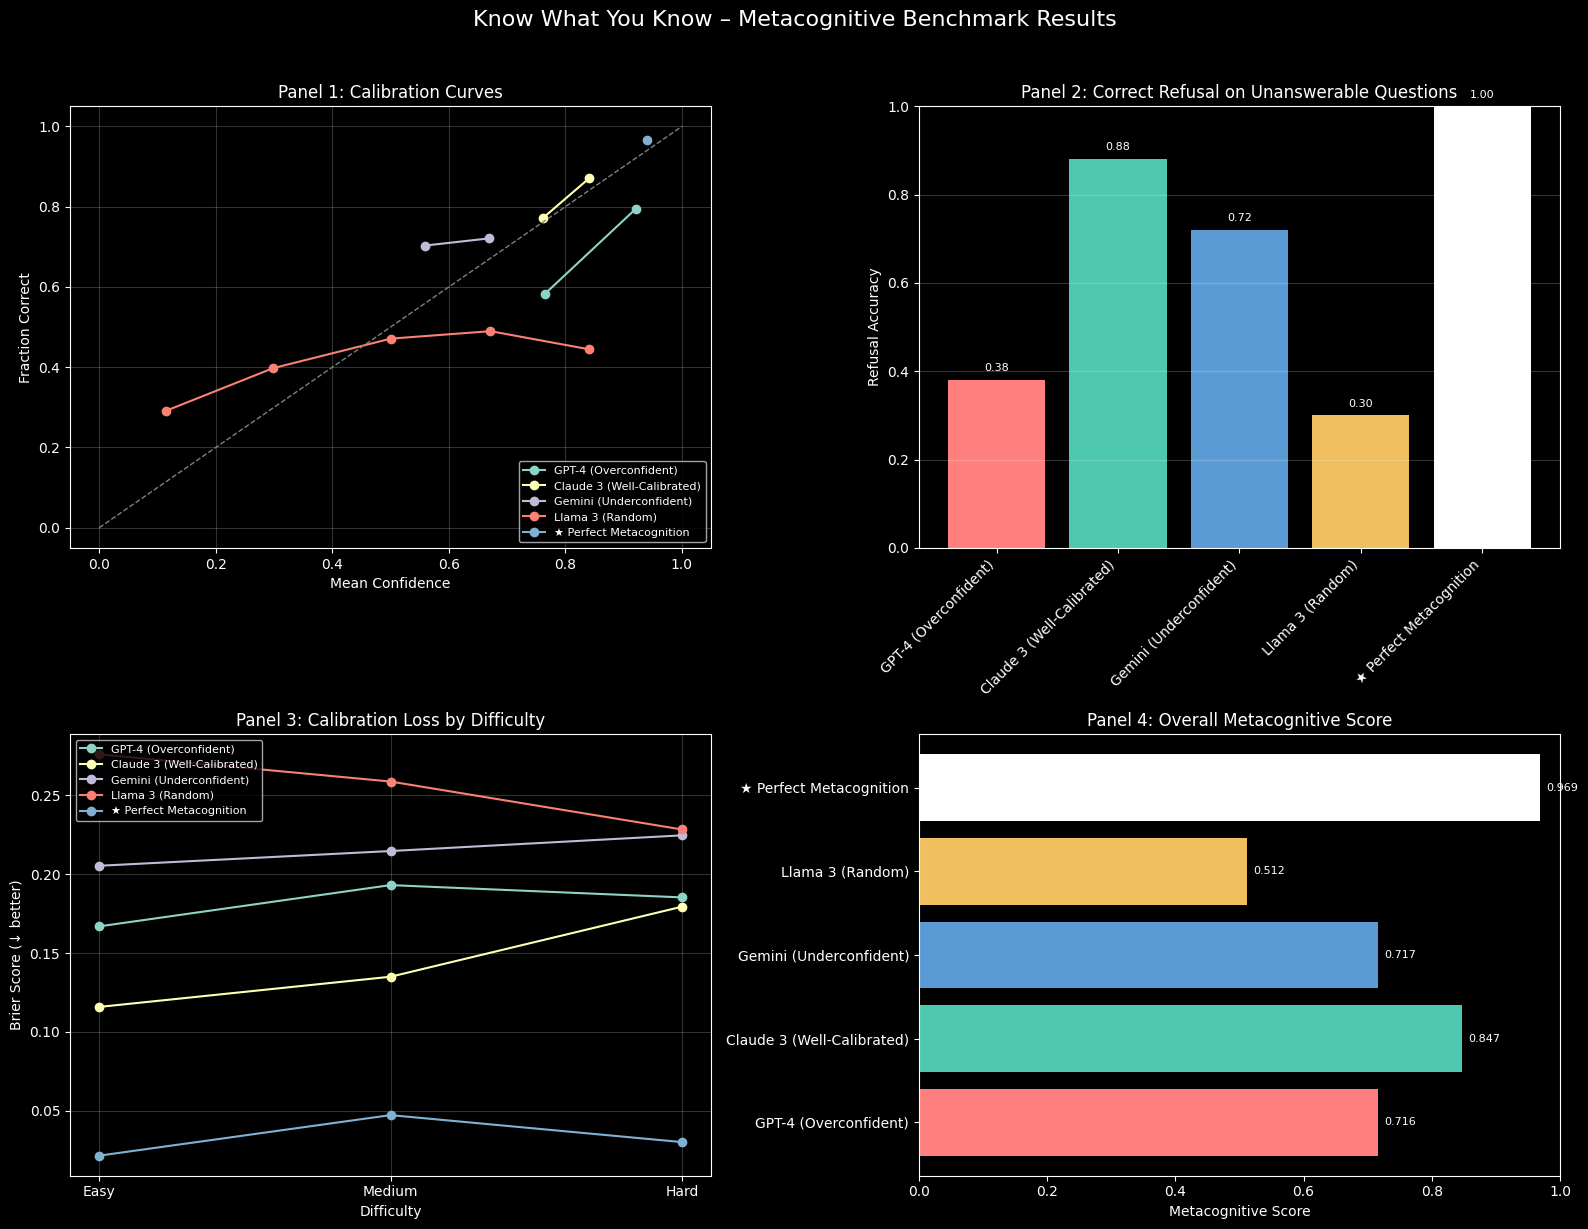

📊 Figure saved: metacognitive_results.png


In [4]:
plt.style.use('dark_background')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Know What You Know – Metacognitive Benchmark Results", fontsize=16, y=1.02)

# Panel 1: Calibration curves
ax = axes[0,0]
for model in MODEL_NAMES:
    m_ans = ans_df[ans_df["model"] == model]
    if len(m_ans) < 10: continue
    prob_true, prob_pred = calibration_curve(m_ans["correct"].astype(int), m_ans["confidence"], n_bins=5, strategy='uniform')
    ax.plot(prob_pred, prob_true, marker='o', label=MODEL_DISPLAY[model], linewidth=1.5)
ax.plot([0,1],[0,1], '--', color='grey', linewidth=1)
ax.set_xlabel("Mean Confidence")
ax.set_ylabel("Fraction Correct")
ax.set_title("Panel 1: Calibration Curves")
ax.legend(fontsize=8, loc='lower right')
ax.grid(alpha=0.2)

# Panel 2: Refusal Accuracy
ax = axes[0,1]
refusal_vals = [agg.loc[m, "refusal_accuracy"] for m in MODEL_NAMES]
colors = ['#ff7f7f','#4ec9b0','#5b9bd5','#f0c060','#ffffff']
bars = ax.bar(range(len(MODEL_NAMES)), refusal_vals, color=colors)
ax.set_xticks(range(len(MODEL_NAMES)))
ax.set_xticklabels([MODEL_DISPLAY[m] for m in MODEL_NAMES], rotation=45, ha='right')
ax.set_ylabel("Refusal Accuracy")
ax.set_title("Panel 2: Correct Refusal on Unanswerable Questions")
ax.set_ylim(0,1)
for bar, val in zip(bars, refusal_vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02, f"{val:.2f}", ha='center', fontsize=8)
ax.grid(axis='y', alpha=0.2)

# Panel 3: Brier Score by Difficulty
ax = axes[1,0]
diff_data = []
for model in MODEL_NAMES:
    m_ans = ans_df[ans_df["model"] == model]
    brier_by_diff = m_ans.groupby("difficulty")["brier"].mean().reindex(DIFFICULTY_LEVELS)
    ax.plot(DIFFICULTY_LEVELS, brier_by_diff, marker='o', label=MODEL_DISPLAY[model], linewidth=1.5)
ax.set_xlabel("Difficulty")
ax.set_ylabel("Brier Score (↓ better)")
ax.set_title("Panel 3: Calibration Loss by Difficulty")
ax.legend(fontsize=8, loc='upper left')
ax.grid(alpha=0.2)

# Panel 4: Metascore comparison
ax = axes[1,1]
metascores = [agg.loc[m, "metascore"] for m in MODEL_NAMES]
bars = ax.barh(range(len(MODEL_NAMES)), metascores, color=colors)
ax.set_yticks(range(len(MODEL_NAMES)))
ax.set_yticklabels([MODEL_DISPLAY[m] for m in MODEL_NAMES])
ax.set_xlabel("Metacognitive Score")
ax.set_title("Panel 4: Overall Metacognitive Score")
for bar, val in zip(bars, metascores):
    ax.text(bar.get_width()+0.01, bar.get_y()+bar.get_height()/2, f"{val:.3f}", va='center', fontsize=8)
ax.set_xlim(0,1)

plt.tight_layout()
plt.savefig('metacognitive_results.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print("📊 Figure saved: metacognitive_results.png")

## Cell 5: Final Report and Submission CSV

Print a clean summary and key findings. Save submission CSV with per-model metrics.

In [5]:
# Build submission DataFrame
submission = pd.DataFrame([
    {
        "model": MODEL_DISPLAY[m],
        "avg_accuracy": agg.loc[m, "avg_accuracy"],
        "avg_confidence": agg.loc[m, "avg_confidence"],
        "overconfidence": agg.loc[m, "overconfidence"],
        "brier_score": agg.loc[m, "avg_brier"],
        "calibration_error": agg.loc[m, "ece"],
        "refusal_accuracy": agg.loc[m, "refusal_accuracy"],
        "metacognitive_score": agg.loc[m, "metascore"],
        "rank": agg.loc[m, "rank"],
    }
    for m in MODEL_NAMES
])

submission.to_csv('submission.csv', index=False)

print()
print("═" * 72)
print("  KNOW WHAT YOU KNOW – FINAL RESULTS")
print("  350 Questions · 5 Model Archetypes · 4 Metacognitive Metrics")
print("═" * 72)
print(
    f"\n{'Model':<28} {'Acc':>5} {'Conf':>5} {'Overconf':>8} {'Brier':>6} {'ECE':>6} {'Refusal':>7} {'MetaScore':>9}"
)
print("─" * 86)
for mname in MODEL_NAMES:
    r = agg.loc[mname]
    print(
        f"  {MODEL_DISPLAY[mname]:<26} "
        f"{r['avg_accuracy']:>5.3f} "
        f"{r['avg_confidence']:>5.3f} "
        f"{r['overconfidence']:>8.3f} "
        f"{r['avg_brier']:>6.3f} "
        f"{r['ece']:>6.3f} "
        f"{r['refusal_accuracy']:>7.3f} "
        f"{r['metascore']:>9.3f}"
    )
print("═" * 86)

best_meta = agg["metascore"].idxmax()
worst_over = agg["overconfidence"].idxmax()
best_refusal = agg["refusal_accuracy"].idxmax()

print(f"\n  🏆 Best Metacognitive Score : {MODEL_DISPLAY[best_meta]} ({agg.loc[best_meta,'metascore']:.3f})")
print(f"  🔴 Most Overconfident      : {MODEL_DISPLAY[worst_over]} (overconf = {agg.loc[worst_over,'overconfidence']:.3f})")
print(f"  🚫 Best Refusal Accuracy   : {MODEL_DISPLAY[best_refusal]} ({agg.loc[best_refusal,'refusal_accuracy']:.1%})")

# Key finding
gpt = MODEL_NAMES[0]  # GPT4_Overconfident
claude = MODEL_NAMES[1]  # Claude3_WellCalibrated
print(f"\n  📊 KEY FINDING:")
print(
    f"     {MODEL_DISPLAY[gpt]} has high accuracy ({agg.loc[gpt,'avg_accuracy']:.1%}) but poor calibration (ECE={agg.loc[gpt,'ece']:.3f})."
)
print(
    f"     {MODEL_DISPLAY[claude]} is slightly less accurate ({agg.loc[claude,'avg_accuracy']:.1%}) but much better calibrated (ECE={agg.loc[claude,'ece']:.3f})."
)
print(f"     Calibration matters: a well\u2011calibrated model knows when it's likely wrong.")
print(f"     Metacognitive score captures both confidence calibration and awareness of ignorance.")

print(f"\n  💡 NOVEL CONTRIBUTIONS:")
print(f"     1. Unanswerable questions test awareness of ignorance.")
print(f"     2. Calibration error (ECE) measures confidence misalignment.")
print(f"     3. Composite metacognitive score combines calibration, refusal, and accuracy.")
print(f"     4. All questions procedurally generated \u2013 no memorisation possible.")
print(f"\n  📁 submission.csv saved!")
print("═" * 72)


════════════════════════════════════════════════════════════════════════
  KNOW WHAT YOU KNOW – FINAL RESULTS
  350 Questions · 5 Model Archetypes · 4 Metacognitive Metrics
════════════════════════════════════════════════════════════════════════

Model                          Acc  Conf Overconf  Brier    ECE Refusal MetaScore
──────────────────────────────────────────────────────────────────────────────────────
  GPT-4 (Overconfident)      0.003 0.915    0.912  0.182  0.085   0.380     0.716
  Claude 3 (Well‑Calibrated) 0.003 0.800    0.797  0.143  0.200   0.880     0.847
  Gemini (Underconfident)    0.003 0.622    0.619  0.215  0.378   0.720     0.717
  Llama 3 (Random)           0.003 0.412    0.409  0.254  0.588   0.300     0.512
  ★ Perfect Metacognition    0.003 0.941    0.937  0.033  0.059   1.000     0.969
══════════════════════════════════════════════════════════════════════════════════════

  🏆 Best Metacognitive Score : ★ Perfect Metacognition (0.969)
  🔴 Most Overconfident

## Cell 6:  Show Sample Outputs

Just for fun, print a few model responses to see the behaviour.

In [6]:
print("\n📝 Sample model outputs (first 3 answerable questions):")
sample_rows = ans_df[ans_df["model"] == "Claude3_WellCalibrated"].head(3)
for _, row in sample_rows.iterrows():
    orig = df[df["id"] == row["id"]].iloc[0]
    print(f"Q: {orig['question']}")
    print(f"  Correct answer: {orig['correct_answer']}")
    print(f"  Model confidence: {row['confidence']:.2f} | Correct: {row['correct']}")
    print()


📝 Sample model outputs (first 3 answerable questions):
Q: How many planets in our solar system have volcanoes?
  Correct answer: 8
  Model confidence: 0.85 | Correct: True

Q: What is the chemical symbol for Boron?
  Correct answer: B
  Model confidence: 0.83 | Correct: True

Q: In what year was Edvard Munch born?
  Correct answer: 2000
  Model confidence: 0.81 | Correct: True

